# 09 — Task B: will this customer leave a 1★ or 2★ review?

**Secondary task.** The prediction moment is **delivery confirmation, before the review request**. At that moment the marketplace knows everything Task A knew, plus how the delivery actually went. The support team can only contact a limited number of customers per day, so the model is judged on how many future bad reviews it puts at the top of each day's list.

| | Task B |
|---|---|
| Target | `review_score ≤ 2` (latest review of the order) |
| Population | Task A population orders that have a review **created on or after the delivery day**. A review written before delivery cannot be prevented by a post-delivery call, so those orders (and orders with no review) are excluded. |
| Inputs | The Task A features, plus delivery facts known at delivery: actual delivery days, days late or early, approval lag, dispatch delay, transit time and the delivered-vs-promised ratio |
| Never inputs | Review score, comment, review dates (the target and its timing) |
| Split | By **delivery date**, the prediction moment: train delivered before 22 Feb 2018 (a 7-day gap lets reviews arrive), validation Mar–Apr 2018, test May 2018 onward |

In [1]:
import sys, time, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, psutil, joblib, optuna, shap
import lightgbm as lgb
from sklearn.metrics import average_precision_score
from olist import config as C
from olist.evaluate import scores, best_f1_threshold, daily_top_k, per_period, bootstrap_ci
from olist.io import load
from olist.modeling import load_task_a, make_model, tree_preprocessor

warnings.filterwarnings("ignore"); optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
proc = psutil.Process(); T0 = time.perf_counter()
rss = lambda: f"{proc.memory_info().rss/1e6:,.0f} MB"
def save(name): plt.savefig(C.FIGURES_DIR / f"09_{name}.png", bbox_inches="tight")
RESULTS = ROOT / "reports" / "results"; MODELS = ROOT / "models"
F_A = json.load(open(MODELS / "task_a_features.json"))

## 1. Build the Task B dataset

In [2]:
pop = load_task_a()
rv = load("reviews").sort_values("review_answer_timestamp").drop_duplicates("order_id", keep="last")
od = load("orders", usecols=["order_id", "order_approved_at", "order_delivered_carrier_date"])
b = pop.merge(rv[["order_id", "review_score", "review_creation_date"]], on="order_id", how="left").merge(od, on="order_id", how="left")
DL, P, E = "order_delivered_customer_date", "order_purchase_timestamp", "order_estimated_delivery_date"
funnel = {"Task A population (delivered)": len(b), "with a review": int(b.review_score.notna().sum())}
b = b[b.review_score.notna()]
b = b[b.review_creation_date >= b[DL].dt.normalize()]
funnel["review created on/after delivery day"] = len(b)
day = 86400
b["actual_delivery_days"] = (b[DL] - b[P]).dt.total_seconds() / day
b["days_late"] = (b[DL].dt.normalize() - b[E]).dt.days
b["delivered_vs_promise"] = b.actual_delivery_days / b.promised_days.clip(lower=1)
b["approval_hours"] = (b.order_approved_at - b[P]).dt.total_seconds() / 3600
b["dispatch_days"] = (b.order_delivered_carrier_date - b.order_approved_at).dt.total_seconds() / day
b["transit_days"] = (b[DL] - b.order_delivered_carrier_date).dt.total_seconds() / day
b["delivered_dow"] = b[DL].dt.dayofweek
b["delivered_late"] = b.late_day
DELIVERY = ["actual_delivery_days", "days_late", "delivered_late", "delivered_vs_promise", "approval_hours",
            "dispatch_days", "transit_days", "delivered_dow"]
FB = F_A + DELIVERY
b["bad_review"] = (b.review_score <= 2).astype(int)
b["deliv_day"] = b[DL].dt.normalize()
b["split"] = np.select([b[DL] < pd.Timestamp("2018-02-22"),
                        (b[DL] >= pd.Timestamp("2018-03-01")) & (b[DL] < pd.Timestamp("2018-05-01")),
                        b[DL] >= pd.Timestamp("2018-05-01")], ["train", "val", "test"], "gap")
b = b.sort_values(DL, kind="mergesort").reset_index(drop=True)
TR, VA, TE = (b[b.split == s].reset_index(drop=True) for s in ["train", "val", "test"])
print(funnel)
pd.DataFrame({s: {"orders": len(d), "bad_review_%": d.bad_review.mean() * 100, "late_%": d.late_day.mean() * 100,
                  "delivered_from": d[DL].min().date(), "delivered_to": d[DL].max().date()}
              for s, d in [("train", TR), ("val", VA), ("test", TE)]}).T

{'Task A population (delivered)': 89795, 'with a review': 89173, 'review created on/after delivery day': 84411}


,orders,bad_review_%,late_%,delivered_from,delivered_to
train,49305,9.504107,1.354832,2017-01-11,2018-02-21
val,12814,11.167473,3.706883,2018-03-01,2018-04-30
test,20723,8.907977,1.336679,2018-05-01,2018-08-29


### When does the review request arrive?

The population drop from 89,173 reviewed orders to 84,411 is small, but it is not random. The check below asks, for every reviewed order, whether the review was created before the parcel arrived.

In [3]:
allrv = pop.merge(rv[["order_id", "review_score", "review_creation_date"]], on="order_id")
allrv["request_before_delivery"] = allrv.review_creation_date < allrv[DL].dt.normalize()
allrv["request_minus_promise_days"] = (allrv.review_creation_date - allrv[E]).dt.days
allrv["request_minus_delivery_days"] = (allrv.review_creation_date - allrv[DL].dt.normalize()).dt.days
timing = allrv.groupby(allrv.late_day.map({0.0: "on time", 1.0: "late"})).agg(
    orders=("order_id", "size"), request_before_delivery_pct=("request_before_delivery", lambda s: s.mean() * 100),
    median_request_minus_promise_days=("request_minus_promise_days", "median"),
    median_request_minus_delivery_days=("request_minus_delivery_days", "median"),
    bad_review_pct=("review_score", lambda s: (s <= 2).mean() * 100))
late_rv = allrv[allrv.late_day == 1]
print(f"bad-review rate of late orders whose request came BEFORE delivery: {(late_rv[late_rv.request_before_delivery].review_score <= 2).mean():.1%}"
      f" | AFTER delivery: {(late_rv[~late_rv.request_before_delivery].review_score <= 2).mean():.1%}")
timing.round(1)

bad-review rate of late orders whose request came BEFORE delivery: 75.7% | AFTER delivery: 26.2%


,orders,request_before_delivery_pct,median_request_minus_promise_days,median_request_minus_delivery_days,bad_review_pct
late_day,,,,,
late,5993,75.8,2.0,-5.0,63.7
on time,83180,0.3,-12.0,1.0,9.4


**Finding.** For **75.8% of late orders the review request is created *before* the parcel arrives**. It typically goes out about 2 days after the promised date, around 5 days before delivery. For on-time orders this happens only 0.3% of the time. Of the late customers asked before delivery, 75.7% leave 1★ or 2★, against 26.2% of late customers asked after delivery.

**Implication.** For three quarters of late orders, a post-delivery intervention comes too late: the review request, and usually the bad review, arrives first. **Task A, at checkout, is the only real lever against lateness.** Task B's population (requests after delivery) therefore contains few late orders (1.35% in training), and the dissatisfaction it predicts is mostly about something else.

## 2. Baselines and models

* **majority:** constant probability;
* **"was it late?" rule:** flag every late delivery. This is the obvious rule a support team would use;
* **days-late logistic regression:** one feature, so it can only learn a single direction;
* **logistic regression** on all Task B features;
* **LightGBM**, tuned with Optuna (40 trials, walk-forward folds on delivery month, early stopping).

In [4]:
folds = []
for m in ["2017-11", "2017-12", "2018-01", "2018-02"]:
    s = pd.Timestamp(m); e = s + pd.offsets.MonthBegin(1)
    folds.append((np.flatnonzero((b[DL] < s - pd.Timedelta(days=7)).to_numpy() & (b.split != "gap").to_numpy()),
                  np.flatnonzero(((b[DL] >= s) & (b[DL] < e)).to_numpy())))
fold_data = []
for tr, va in folds:
    pre = tree_preprocessor(FB).fit(b[FB].iloc[tr], b.bad_review.iloc[tr])
    fold_data.append((pre.transform(b[FB].iloc[tr]), b.bad_review.iloc[tr].to_numpy(), pre.transform(b[FB].iloc[va]), b.bad_review.iloc[va].to_numpy()))

def objective(trial):
    params = dict(learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
                  num_leaves=trial.suggest_int("num_leaves", 8, 128, log=True),
                  min_child_samples=trial.suggest_int("min_child_samples", 20, 500, log=True),
                  subsample=trial.suggest_float("subsample", 0.6, 1.0), subsample_freq=1,
                  colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
                  reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True))
    aps, its = [], []
    for Xtr, ytr, Xva, yva in fold_data:
        m = lgb.LGBMClassifier(n_estimators=2000, random_state=C.SEED, n_jobs=5, verbose=-1, metric="average_precision", **params)
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], callbacks=[lgb.early_stopping(100, verbose=False)])
        aps.append(average_precision_score(yva, m.predict_proba(Xva)[:, 1])); its.append(m.best_iteration_ or 2000)
    trial.set_user_attr("iters", its)
    return float(np.mean(aps))
t = time.perf_counter()
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=C.SEED))
study.optimize(objective, n_trials=40, n_jobs=4)
lgb_b = {**study.best_params, "subsample_freq": 1, "n_estimators": int(np.median(study.best_trial.user_attrs["iters"])), "n_jobs": 8}
print(f"LightGBM search: 40 trials in {time.perf_counter()-t:.0f}s, best walk-forward PR-AUC {study.best_value:.4f}")

from olist.baselines import MajorityBaseline
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
class LateRule:
    def predict_proba(self, X):
        p = X["delivered_late"].to_numpy(dtype=float); return np.column_stack([1 - p, p])
fitted = {
    "majority": (MajorityBaseline().fit(TR[FB], TR.bad_review), FB),
    "rule: delivered late": (LateRule(), FB),
    "logreg: days_late only": (make_pipeline(StandardScaler(), LogisticRegression()).fit(TR[["days_late"]], TR.bad_review), ["days_late"]),
    "logistic regression": (make_model("logreg", FB, C=0.1, l1_ratio=0.5).fit(TR[FB], TR.bad_review), FB),
    "LightGBM": (make_model("lgbm", FB, **lgb_b).fit(TR[FB], TR.bad_review), FB),
}
joblib.dump(fitted["LightGBM"][0], MODELS / "task_b_lgbm.joblib")
PB = {k: {s: m.predict_proba(d[f])[:, 1] for s, d in [("val", VA), ("test", TE)]} for k, (m, f) in fitted.items()}

K = 20   # customers support can call per day
rows = []
for k in fitted:
    thr = 0.5 if k in ("majority", "rule: delivered late") else best_f1_threshold(VA.bad_review, PB[k]["val"])
    st = scores(TE.bad_review, PB[k]["test"], thr)
    tk = daily_top_k(TE.bad_review, PB[k]["test"], TE.deliv_day, K)
    rows.append({"model": k, "val_pr_auc": scores(VA.bad_review, PB[k]["val"])["pr_auc"], "test_pr_auc": st["pr_auc"],
                 "test_roc_auc": st["roc_auc"], "threshold": thr, "test_precision": st["precision"], "test_recall": st["recall"],
                 "test_f1": st["f1"], f"precision@{K}/day": tk["precision"], f"bad reviews caught by {K} calls/day": tk["recall"]})
resB = pd.DataFrame(rows).set_index("model")
resB.to_csv(RESULTS / "09_task_b_results.csv")
print(f"test: {len(TE):,} orders, {TE.bad_review.mean():.1%} bad reviews, {TE.deliv_day.nunique()} delivery days")
resB.round(3)

LightGBM search: 40 trials in 28s, best walk-forward PR-AUC 0.2566


test: 20,723 orders, 8.9% bad reviews, 116 delivery days


,val_pr_auc,test_pr_auc,test_roc_auc,threshold,test_precision,test_recall,test_f1,precision@20/day,bad reviews caught by 20 calls/day
model,,,,,,,,,
majority,0.112,0.089,0.500,0.500,0.000,0.000,0.000,0.105,0.112
rule: delivered late,0.129,0.093,0.511,0.500,0.217,0.033,0.057,0.119,0.127
logreg: days_late only,0.155,0.098,0.500,0.107,0.098,0.166,0.123,0.112,0.120
logistic regression,0.294,0.195,0.656,0.159,0.249,0.258,0.254,0.229,0.244
LightGBM,0.293,0.196,0.652,0.129,0.239,0.311,0.270,0.230,0.245


**Finding.** On the test period (20,723 orders, 8.9% bad reviews), logistic regression (PR-AUC 0.195) and LightGBM (0.196) both reach **2.2× the base rate**. The obvious rules hardly work inside this population: "was it late?" scores 0.093 and days-late alone 0.098, with ROC 0.50 on test. A support team calling the **20 riskiest customers per delivery day** would reach a future 1–2★ reviewer **23% of the time, against 10.5% for random calls**, and would cover 24.5% of all bad reviews. With 5 calls per day the hit rate is 31%.

## 3. How much comes from the delivery itself?

In [5]:
abl = {}
for name, feats in [("checkout features only (Task A set)", F_A), ("delivery facts only", DELIVERY), ("both", FB)]:
    m = make_model("lgbm", feats, **lgb_b).fit(TR[feats], TR.bad_review)
    p = m.predict_proba(TE[feats])[:, 1]
    abl[name] = {"test_pr_auc": average_precision_score(TE.bad_review, p),
                 f"precision@{K}/day": daily_top_k(TE.bad_review, p, TE.deliv_day, K)["precision"]}
abl = pd.DataFrame(abl).T
abl.to_csv(RESULTS / "09_task_b_feature_ablation.csv")
abl.round(3)

,test_pr_auc,precision@20/day
checkout features only (Task A set),0.181,0.221
delivery facts only,0.126,0.138
both,0.196,0.230


## 4. Ranking quality for the support team

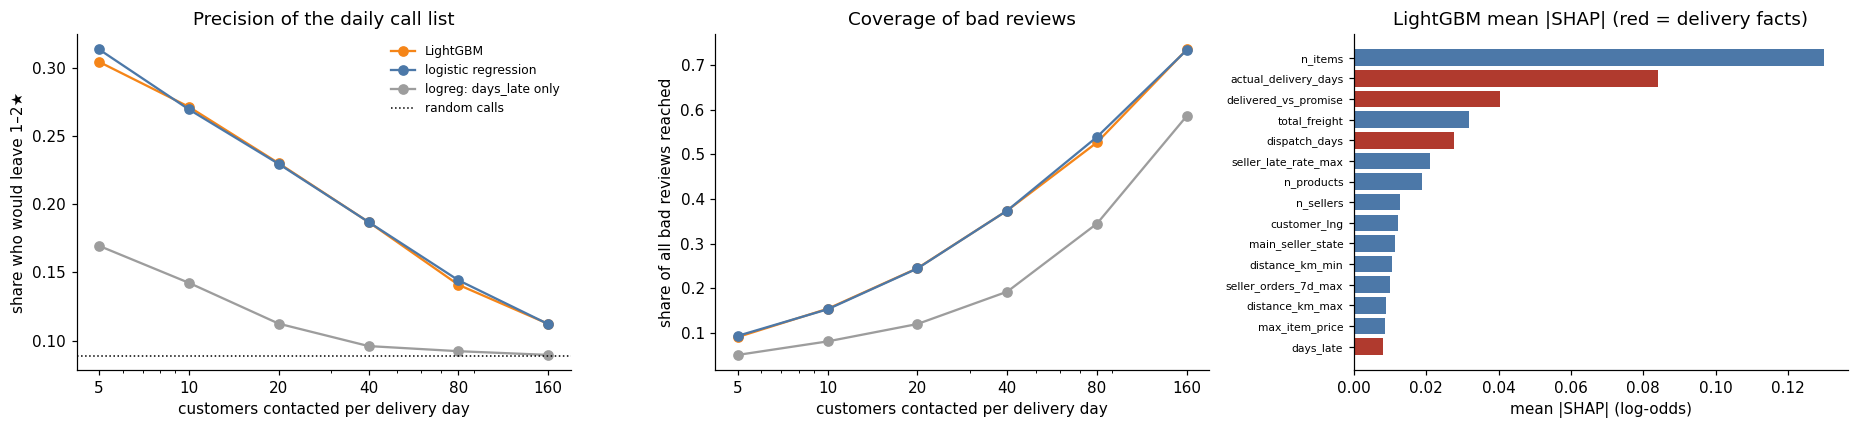

,orders,base_rate_%,pr_auc,roc_auc,lift
period,,,,,
2018-05,6733,8.703,0.215,0.670,2.468
2018-06,6459,9.429,0.209,0.662,2.219
2018-07,5740,8.641,0.167,0.625,1.938
2018-08,1791,8.654,0.185,0.647,2.135


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
ks = [5, 10, 20, 40, 80, 160]
for k, c in [("LightGBM", "#F58518"), ("logistic regression", "#4C78A8"), ("logreg: days_late only", "#9D9D9D")]:
    axes[0].plot(ks, [daily_top_k(TE.bad_review, PB[k]["test"], TE.deliv_day, kk)["precision"] for kk in ks], marker="o", color=c, label=k)
    axes[1].plot(ks, [daily_top_k(TE.bad_review, PB[k]["test"], TE.deliv_day, kk)["recall"] for kk in ks], marker="o", color=c, label=k)
axes[0].axhline(TE.bad_review.mean(), color="k", ls=":", lw=1, label="random calls")
axes[0].set_xscale("log"); axes[0].set_xticks(ks, ks); axes[0].set_xlabel("customers contacted per delivery day"); axes[0].set_ylabel("share who would leave 1–2★")
axes[0].set_title("Precision of the daily call list"); axes[0].legend(frameon=False, fontsize=8)
axes[1].set_xscale("log"); axes[1].set_xticks(ks, ks); axes[1].set_xlabel("customers contacted per delivery day"); axes[1].set_ylabel("share of all bad reviews reached")
axes[1].set_title("Coverage of bad reviews")
mdl = fitted["LightGBM"][0]
Xs = mdl.named_steps["pre"].transform(TE[FB]).sample(3000, random_state=C.SEED)
sv = shap.TreeExplainer(mdl.named_steps["clf"])(Xs)
imp = pd.Series(np.abs(sv.values).mean(0), index=Xs.columns).sort_values(ascending=False).head(15)[::-1]
axes[2].barh(imp.index, imp, color=np.where(imp.index.isin(DELIVERY), "#B03A2E", "#4C78A8")); axes[2].tick_params(axis="y", labelsize=7)
axes[2].set_title("LightGBM mean |SHAP| (red = delivery facts)"); axes[2].set_xlabel("mean |SHAP| (log-odds)")
plt.tight_layout(); save("task_b"); plt.show()
pm = per_period(TE.bad_review, PB["LightGBM"]["test"], TE[DL].dt.to_period("M").astype(str))
pm.round(3)

**Finding.** Most of the signal comes from **what was ordered and from where**, not from how the delivery went. Checkout features alone reach 0.181, delivery facts alone 0.126, and both together 0.196. The strongest single feature is **`n_items`**: multi-item orders are a major source of unhappiness, plausibly because they arrive split or partially. After it come actual delivery days, delivered-vs-promised and dispatch delay. Performance is steady month to month (lift 1.9–2.5) because, unlike lateness, the bad-review rate barely drifts (8.6–9.4%).

**Decision.** Task B is useful as a **daily call list** for support: about 2–3× better than random at every list size. Its biggest lever is checking on multi-item orders after delivery.

In [7]:
print(f"notebook runtime {time.perf_counter()-T0:.1f}s | final RSS {rss()}")

notebook runtime 34.9s | final RSS 834 MB
